# Simulation summary visualization

Load the final `summary.csv` and compare the three estimators using MSE only. Each figure fixes the `n2/n1` multiplier; columns are the bias settings (`delta_f = delta_c = delta`), and lines distinguish the estimators.

In [18]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
methods = ['eb', 'ppi', 'ppi_plus_plus', 'ppi_plus_plus_oracle']
method_labels = {'eb': 'EB', 'ppi': 'PPI', 'ppi_plus_plus': 'PPI++', 'ppi_plus_plus_oracle': 'PPI++ Oracle'}


In [19]:
SUMMARY_PATH = Path('../data/summary_small_n.csv')
if not SUMMARY_PATH.exists():
    candidates = sorted(Path('../results').glob('**/summary.csv'))
    if not candidates:
        raise FileNotFoundError('No summary.csv found. Run combine_results.py first.')
    SUMMARY_PATH = candidates[0]
summary = pd.read_csv(SUMMARY_PATH)

# n2/n1 is the requested multiplier. Keep a rounded value for stable grouping
# when the input contains decimal sample-size multipliers.
summary['multiplier'] = (summary['n2'] / summary['n1']).round(10)

# delta_f and delta_c are intended to be the same bias parameter.
if not np.allclose(summary['delta_f'], summary['delta_c']):
    raise ValueError('Expected delta_f and delta_c to be equal.')
summary['delta'] = summary['delta_f']

multipliers = sorted(summary['multiplier'].unique())
deltas = sorted(summary['delta'].unique())
rhos = sorted(summary['rho'].unique())
summary[['n1', 'n2', 'multiplier', 'delta', 'rho']].head()
summary

,n1,n2,mu,delta_f,delta_c,rho,sigma1,sigma2,sigma3,n_replicates,...,ppi_variance,ppi_mse,ppi_plus_plus_bias,ppi_plus_plus_variance,ppi_plus_plus_mse,ppi_plus_plus_oracle_bias,ppi_plus_plus_oracle_variance,ppi_plus_plus_oracle_mse,multiplier,delta
0,100,100,3.0,0.0,0.0,0.00,1.0,1.0,1.0,10000,...,0.029952,0.029953,-2.087925e-03,0.009991,0.009994,-0.002066,0.009958,0.009961,1.0,0.0
1,100,100,3.0,0.0,0.0,0.25,1.0,1.0,1.0,10000,...,0.024898,0.024899,1.278367e-03,0.009922,0.009922,0.001318,0.009861,0.009862,1.0,0.0
2,100,100,3.0,0.0,0.0,0.50,1.0,1.0,1.0,10000,...,0.019836,0.019834,-4.570080e-04,0.008799,0.008798,-0.000481,0.008737,0.008736,1.0,0.0
3,100,100,3.0,0.0,0.0,0.75,1.0,1.0,1.0,10000,...,0.014940,0.014938,-5.250057e-04,0.007398,0.007398,-0.000577,0.007337,0.007337,1.0,0.0
4,100,100,3.0,0.0,0.0,0.80,1.0,1.0,1.0,10000,...,0.013456,0.013457,-1.271133e-03,0.006718,0.006719,-0.001310,0.006667,0.006668,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,1000,50000,3.0,10.0,10.0,0.00,1.0,1.0,1.0,10000,...,0.002036,0.002035,2.797808e-04,0.001005,0.001004,0.000282,0.001003,0.001003,50.0,10.0
746,1000,50000,3.0,10.0,10.0,0.25,1.0,1.0,1.0,10000,...,0.001523,0.001523,1.482318e-07,0.000927,0.000927,0.000002,0.000926,0.000926,50.0,10.0
747,1000,50000,3.0,10.0,10.0,0.50,1.0,1.0,1.0,10000,...,0.000998,0.000998,-1.011989e-04,0.000744,0.000744,-0.000092,0.000742,0.000742,50.0,10.0
748,1000,50000,3.0,10.0,10.0,0.75,1.0,1.0,1.0,10000,...,0.000528,0.000528,-1.549694e-04,0.000458,0.000458,-0.000153,0.000456,0.000456,50.0,10.0


## MSE by multiplier

Each multiplier gets its own figure. Rows are rho, columns are delta (the common bias setting), and the colored lines are the three estimators plotted across `n1`.

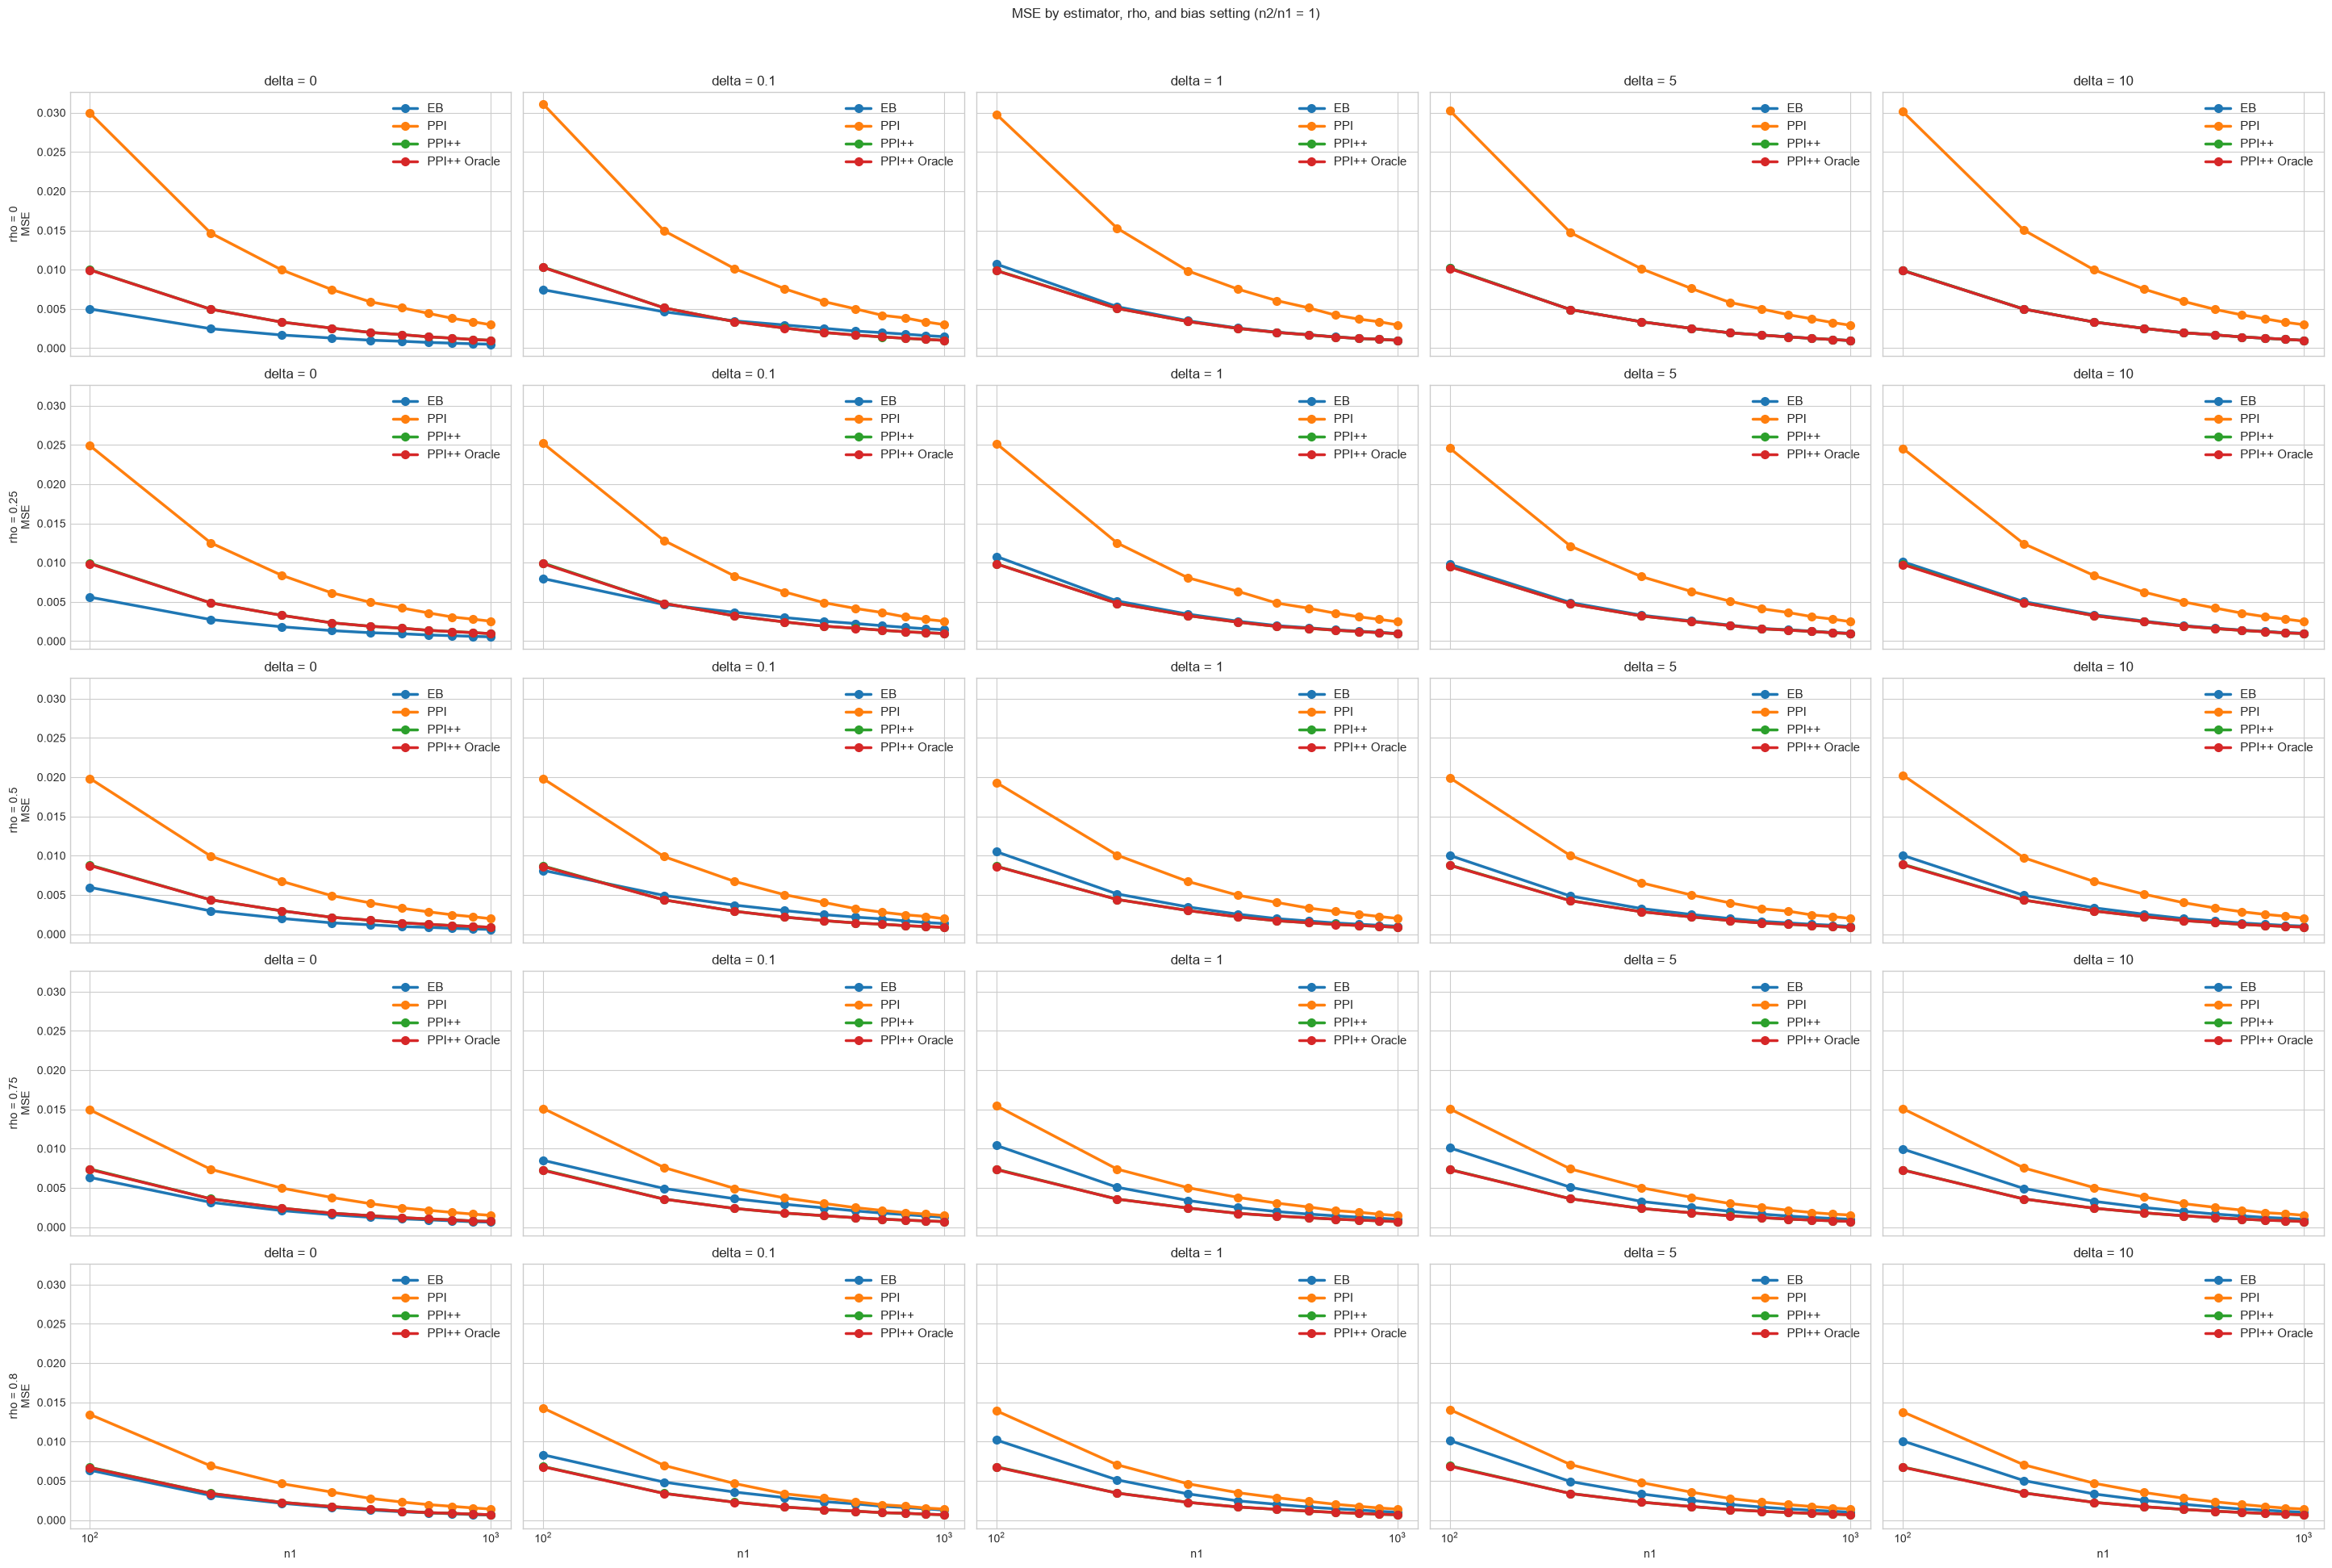

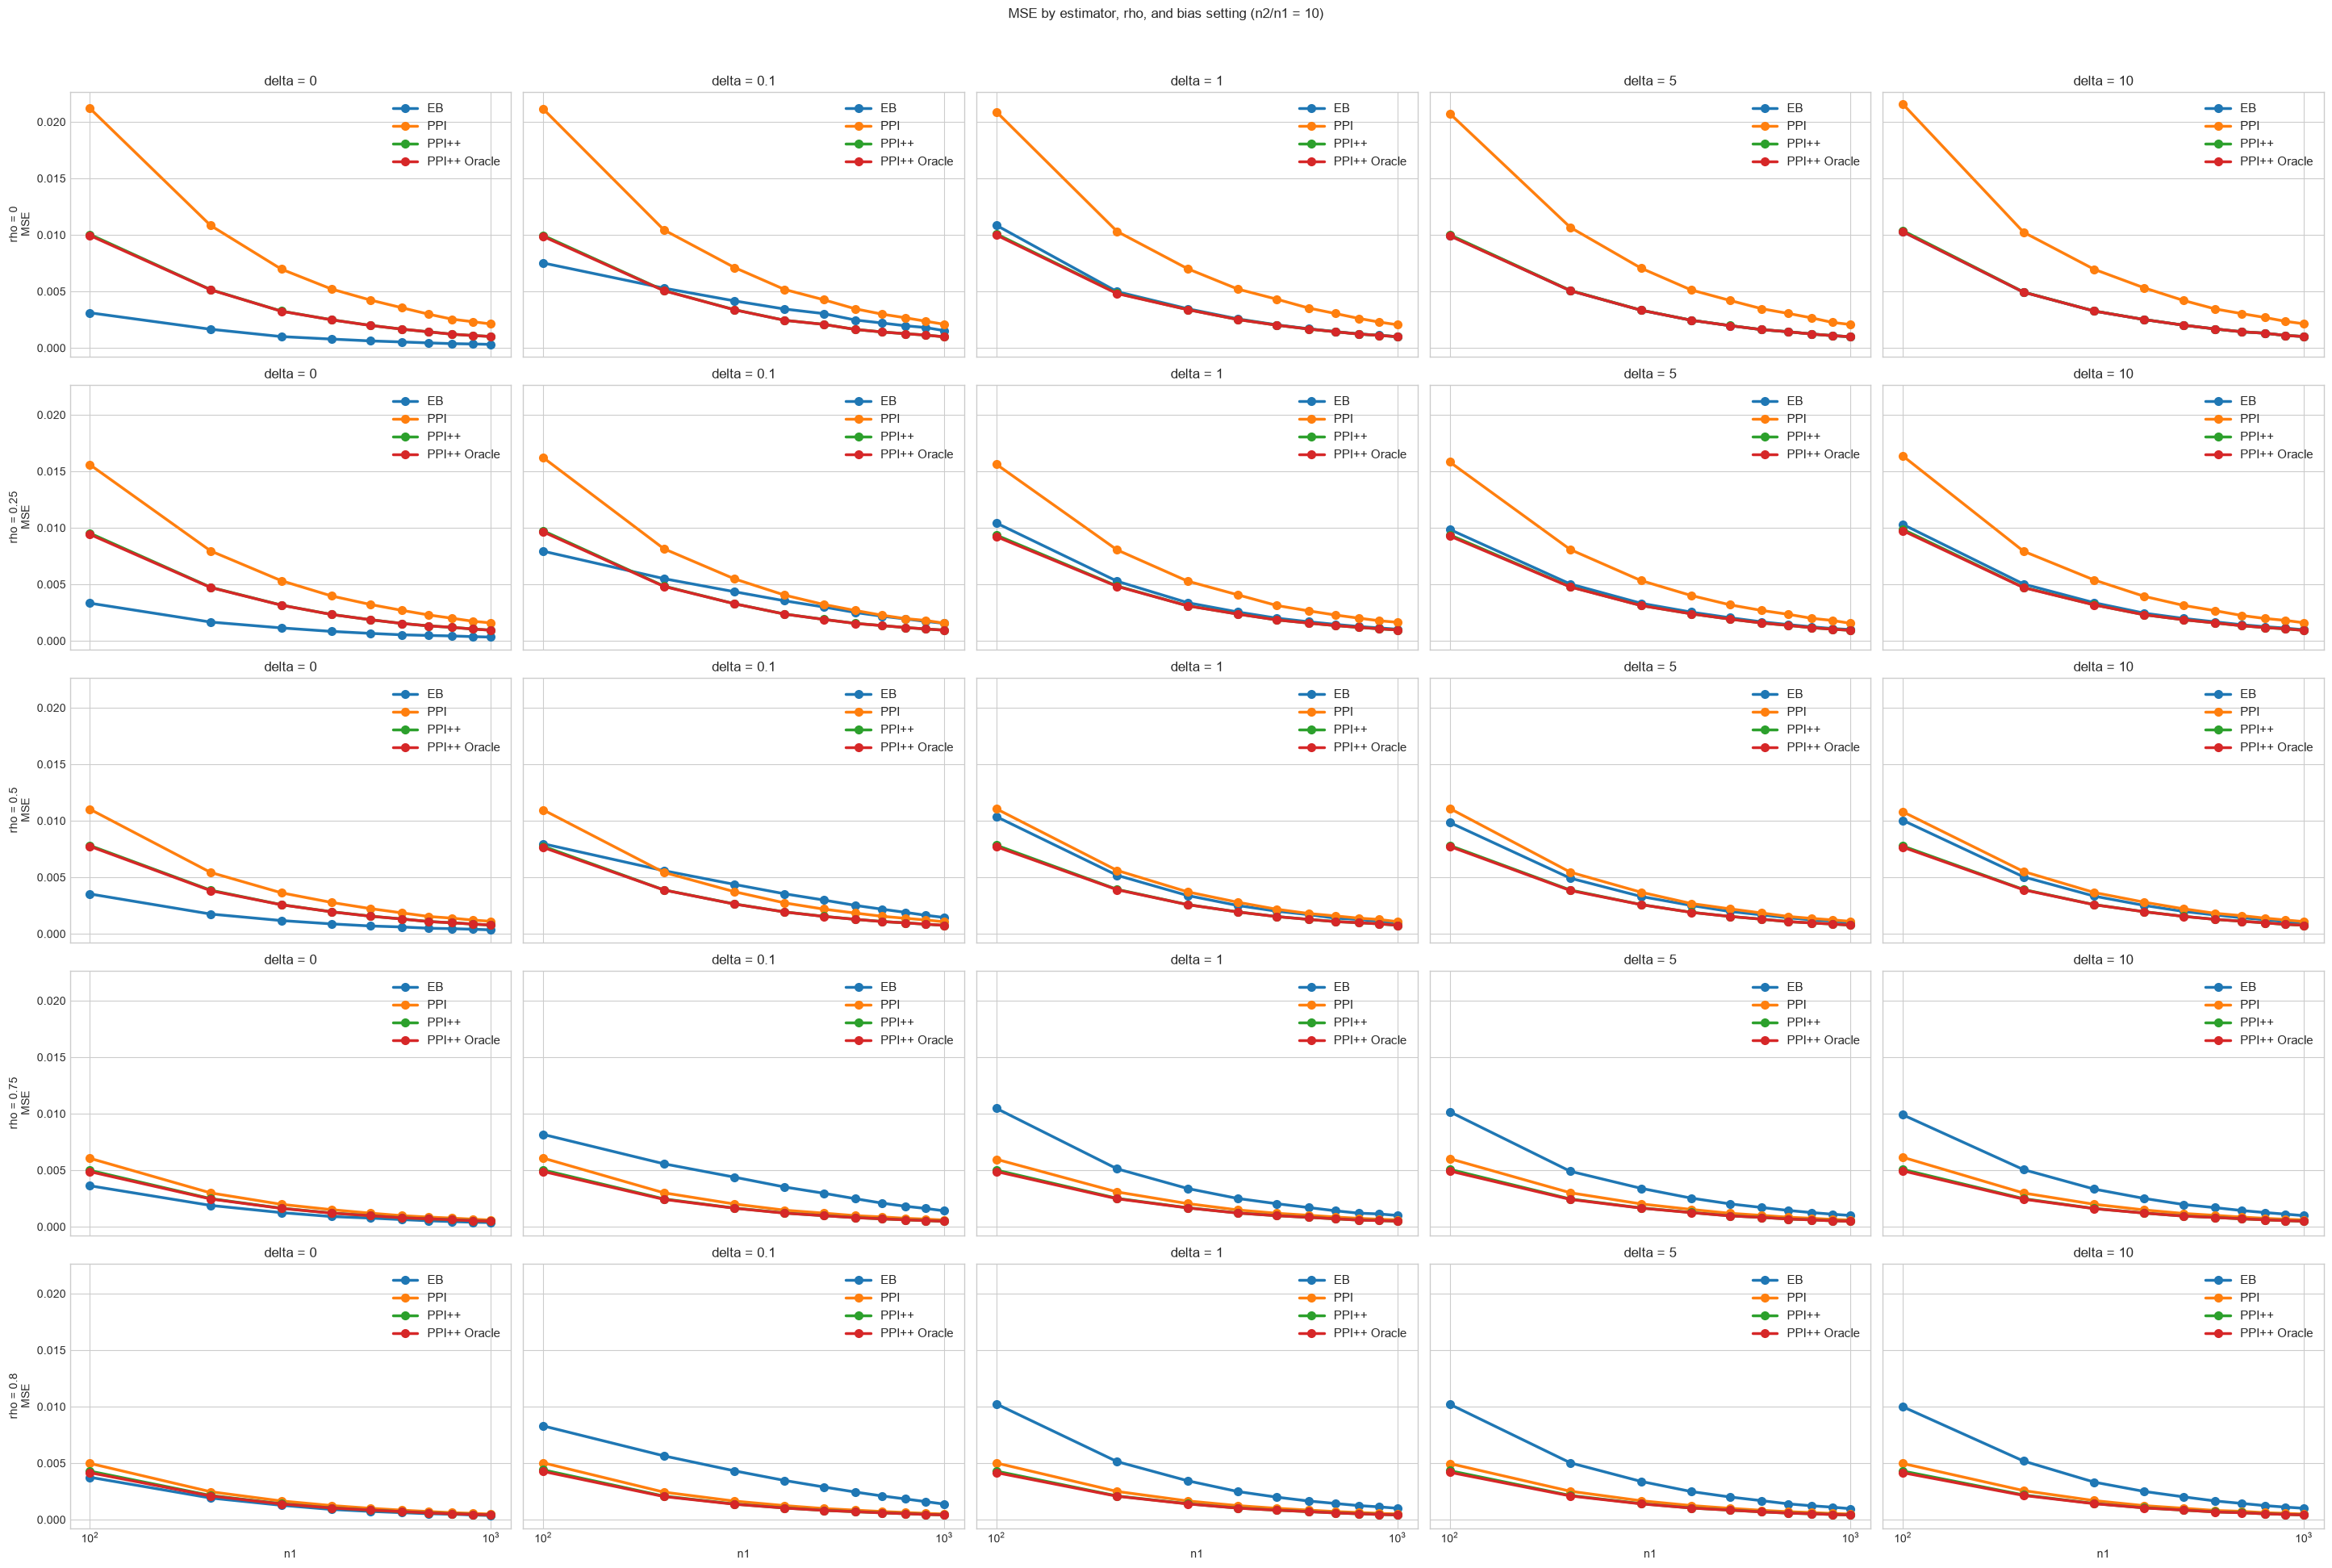

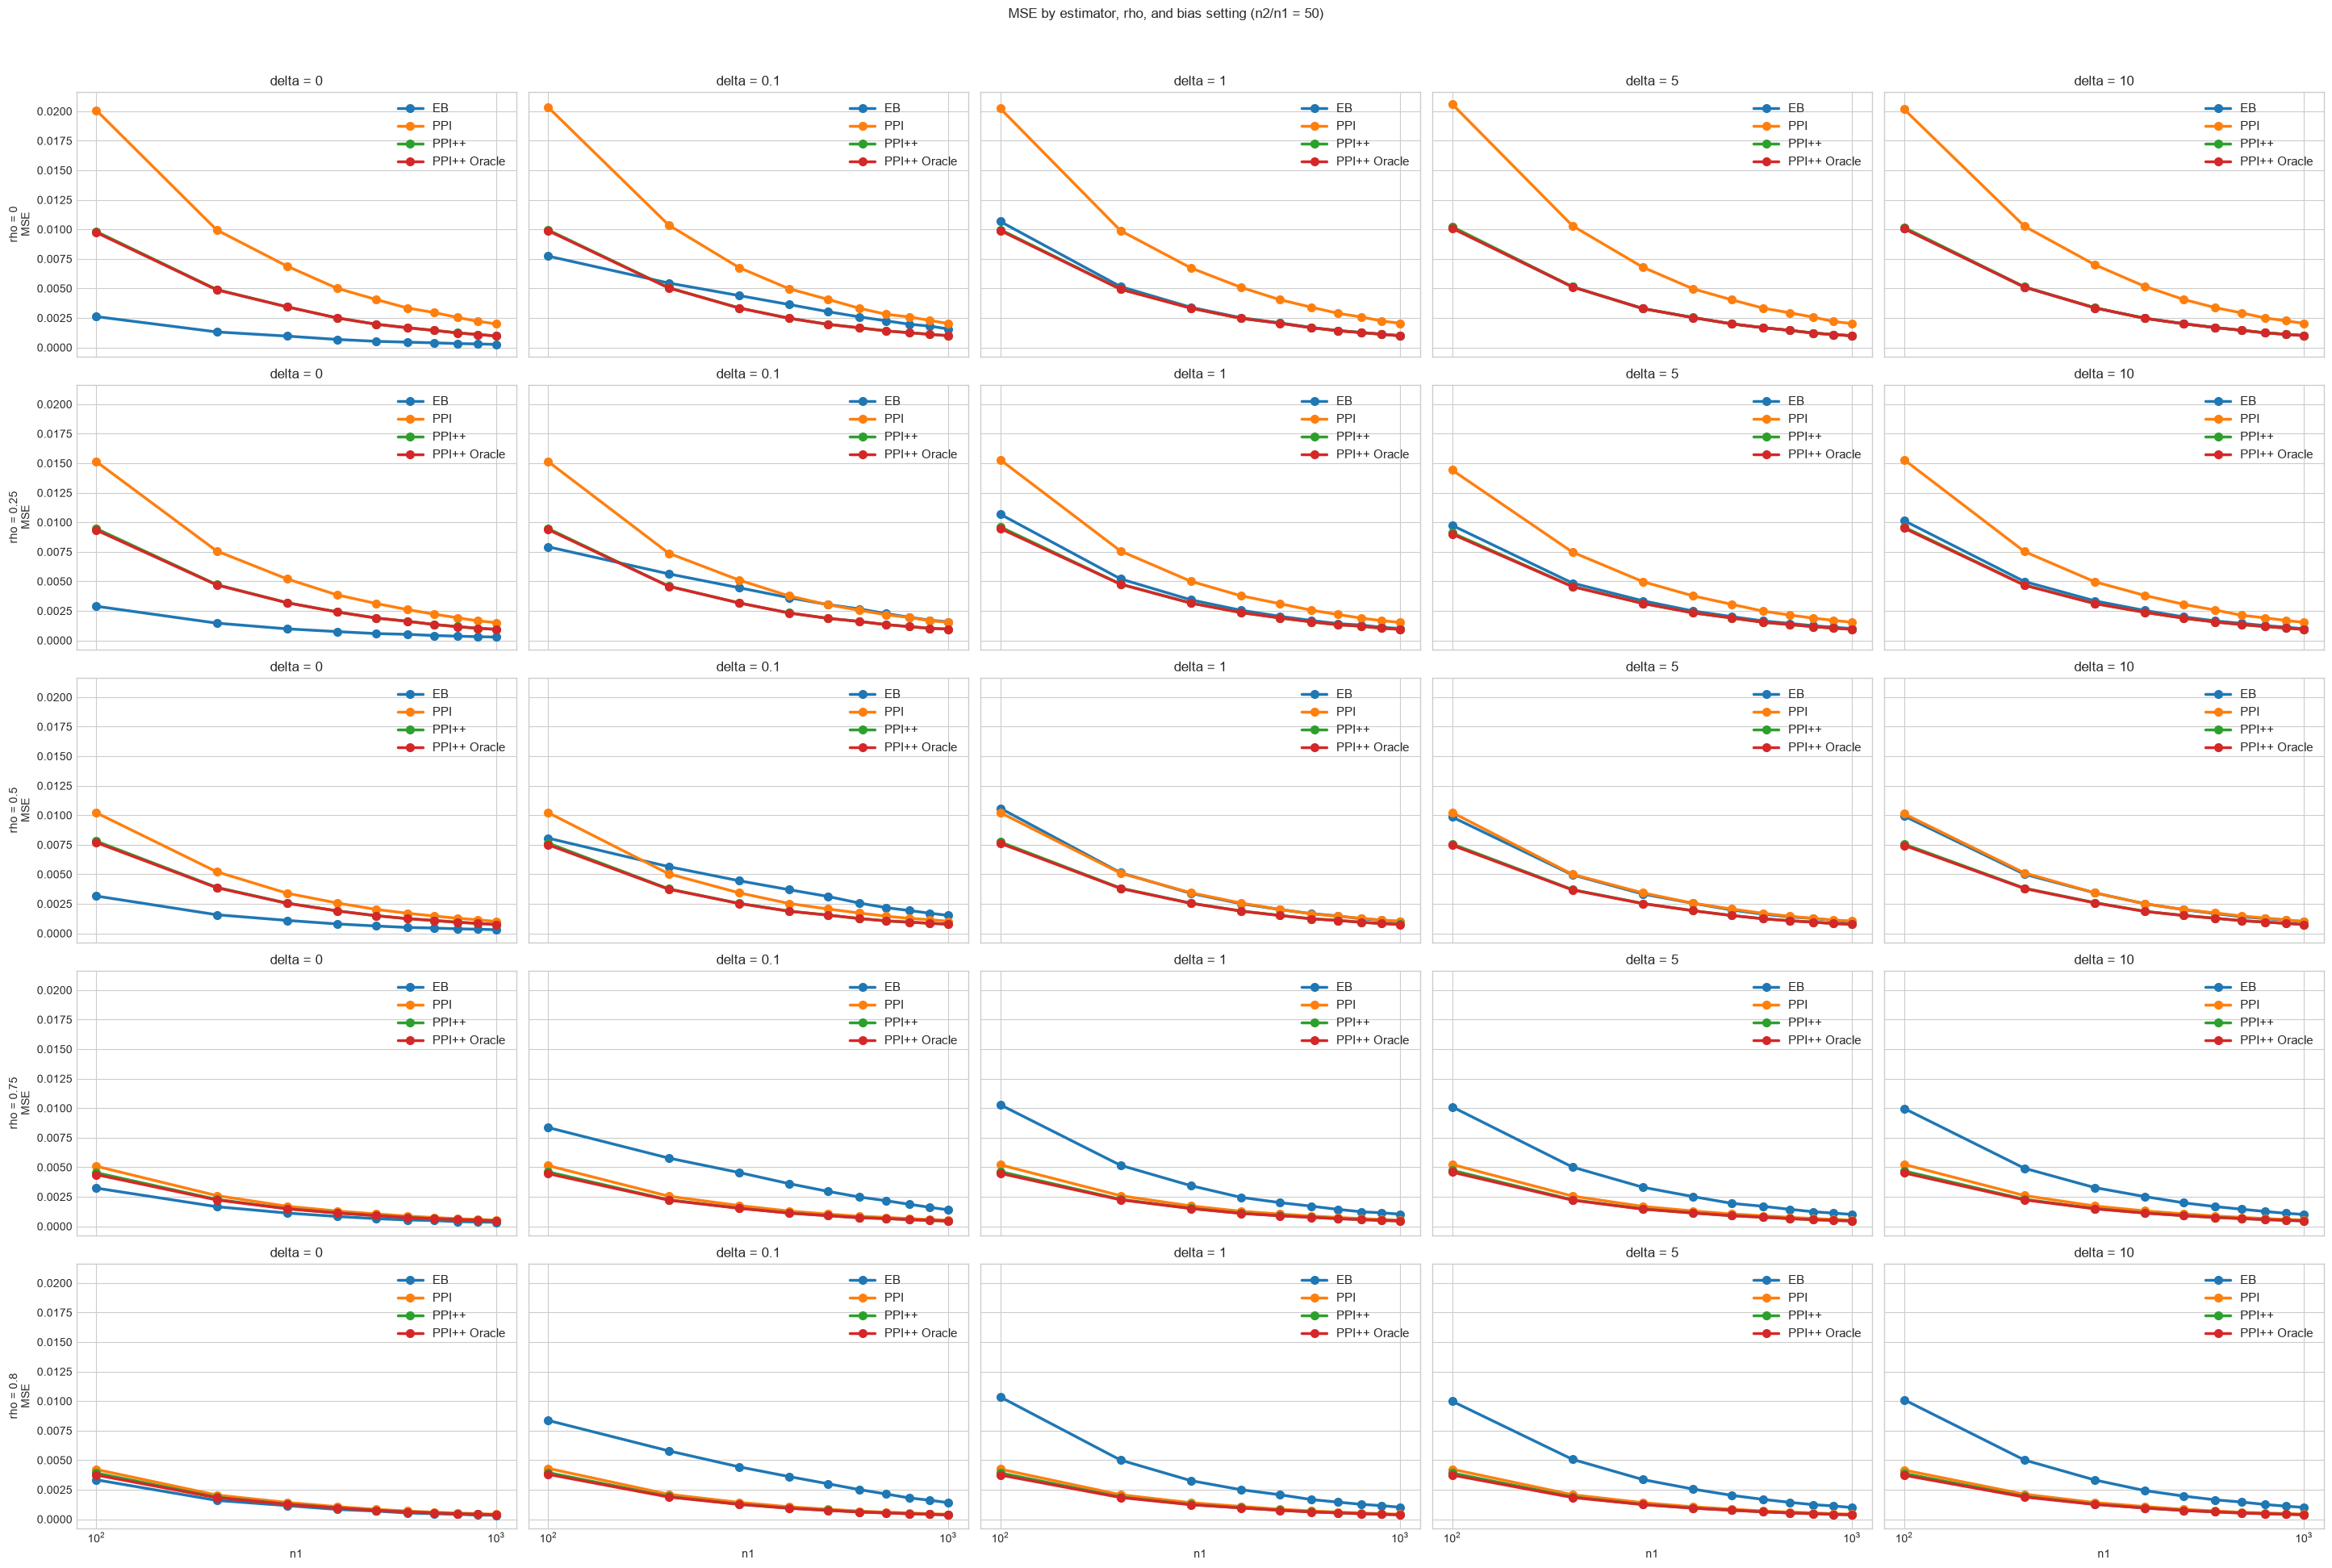

In [21]:
for multiplier in multipliers:
    selected = summary[summary['multiplier'] == multiplier]
    fig, axes = plt.subplots(
        len(rhos), len(deltas),
        figsize=(5.8 * len(deltas), 3.8 * len(rhos)),
        sharex=True, sharey=True, squeeze=False,
    )

    for row, rho in enumerate(rhos):
        for col, delta in enumerate(deltas):
            ax = axes[row, col]
            panel = selected[(selected['rho'] == rho) & (selected['delta'] == delta)]
            for method in methods:
                mse_column = f'{method}_mse'
                curve = panel.sort_values('n1')
                ax.plot(curve['n1'], curve[mse_column], marker='o',
                        linewidth=2.5, markersize=7, label=method_labels[method])
            ax.set_xscale('log')
            ax.set_title(f'delta = {delta:g}')
            if col == 0:
                ax.set_ylabel(f'rho = {rho:g}\nMSE')
            if row == len(rhos) - 1:
                ax.set_xlabel('n1')
            ax.legend(fontsize=11)

    fig.suptitle(f'MSE by estimator, rho, and bias setting (n2/n1 = {multiplier:g})', y=1.02)
    plt.tight_layout()
    plt.show()
